# 09 - Validation Error Analysis

Inspect saved E1 MobileNetV2 validation predictions and compare per-class F1 with E0. No model is loaded or run. Only the 12 selected original validation images are opened; raw files and existing experiment evidence remain unchanged.

## 1. Project root and saved evaluation inputs

Follow the structural project-root convention and preserve IDs as strings. Verify both experiments against the same saved validation rows and class mapping. Input SHA256 values are checked again after analysis.

In [1]:
from pathlib import Path
import hashlib
import json
import random
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageFile
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support
from IPython.display import display

get_ipython().run_line_magic("matplotlib", "inline")


def find_project_root(start):
    start = Path(start).resolve()
    for candidate in (start, *start.parents):
        if (candidate / "requirements.txt").is_file() and (candidate / "notebooks/00_Environment_Check.ipynb").is_file():
            return candidate
    raise FileNotFoundError("Open this project root or its notebooks directory.")


def sha256(path):
    with path.open("rb") as stream:
        return hashlib.file_digest(stream, "sha256").hexdigest()


def read_strings(path):
    return pd.read_csv(path, dtype=str, keep_default_na=False, na_filter=False)


checks = {}


def require(name, condition):
    checks[name] = bool(condition)
    assert checks[name], name
    print(name + ": PASS")


PROJECT_ROOT = find_project_root(Path.cwd())
require("root_and_notebooks_path_resolution", all(
    find_project_root(start) == PROJECT_ROOT
    for start in [PROJECT_ROOT, PROJECT_ROOT / "notebooks"]))
require("existing_project_venv", Path(sys.prefix).resolve() == PROJECT_ROOT / ".venv")
require("strict_image_decoding", not ImageFile.LOAD_TRUNCATED_IMAGES)
SPLIT_PATH = PROJECT_ROOT / "data/processed/split_manifest.csv"
MAPPING_PATH = PROJECT_ROOT / "data/processed/class_mapping.json"
RUNS = {"E0": "E0_reference_cnn_seed42_attempt2", "E1": "E1_mobilenetv2_frozen_seed42"}
paths = {"split": SPLIT_PATH, "mapping": MAPPING_PATH}
for experiment, run in RUNS.items():
    for filename in ["validation_predictions.csv", "validation_metrics.json", "classification_report.csv"]:
        paths[f"{experiment}/{filename}"] = PROJECT_ROOT / "outputs/metrics" / run / filename
input_hashes = {name: sha256(path) for name, path in paths.items()}
split = read_strings(SPLIT_PATH)
validation = split.loc[split["split"].eq("validation")].reset_index(drop=True)
mapping = json.loads(MAPPING_PATH.read_text(encoding="utf-8"))
classes = [mapping["index_to_class"][str(i)] for i in range(8)]
require("validation_unique_12733_ids", len(validation) == 12733 and validation["image_id"].is_unique)
require("class_mapping_round_trip", all(mapping["class_to_index"][name] == i for i, name in enumerate(classes)))
print("Project:", PROJECT_ROOT)
print("Python:", sys.executable)

root_and_notebooks_path_resolution: PASS
existing_project_venv: PASS
strict_image_decoding: PASS


validation_unique_12733_ids: PASS
class_mapping_round_trip: PASS
Project: C:\Users\leoca\Kaggle-Competition
Python: C:\Users\leoca\Kaggle-Competition\.venv\Scripts\python.exe


## 2. Recomputed errors, confusion pairs and per-class F1

All statistics use the full saved validation predictions, not the gallery. Compare recomputed confusion counts and class metrics with both saved JSON and CSV reports (absolute tolerance 1e-12). Confidence values are maximum softmax scores, not calibrated certainty.

In [2]:
predictions = {}
metrics = {}
class_results = {}
confusions = {}
for experiment in RUNS:
    predicted = read_strings(paths[f"{experiment}/validation_predictions.csv"])
    saved = json.loads(paths[f"{experiment}/validation_metrics.json"].read_text(encoding="utf-8"))
    report = pd.read_csv(paths[f"{experiment}/classification_report.csv"], float_precision="round_trip")
    require(experiment + "_saved_checks_passed", saved["status"] == "passed"
            and saved["run_name"] == RUNS[experiment] and saved["samples"] == 12733
            and not saved.get("failed_checks") and not saved.get("warnings")
            and all(value is True for value in saved["checks"].values()))
    require(experiment + "_mapping_and_split_hash", saved["class_mapping"] == mapping
            and saved["input_sha256"]["data/processed/split_manifest.csv"] == input_hashes["split"]
            and saved["input_sha256"]["data/processed/class_mapping.json"] == input_hashes["mapping"])
    require(experiment + "_ids_order_and_true_labels", len(predicted) == len(validation)
            and predicted["image_id"].is_unique
            and predicted["image_id"].tolist() == validation["image_id"].tolist()
            and predicted["true_class"].tolist() == validation["class"].tolist())
    confidence = predicted["max_softmax_confidence"].astype(float)
    require(experiment + "_classes_and_confidences", predicted["predicted_class"].isin(classes).all()
            and np.isfinite(confidence).all() and confidence.between(0, 1).all())
    predicted["max_softmax_confidence"] = confidence
    cm = confusion_matrix(predicted["true_class"], predicted["predicted_class"], labels=classes)
    precision, recall, f1, support = precision_recall_fscore_support(
        predicted["true_class"], predicted["predicted_class"], labels=classes, zero_division=0)
    np.testing.assert_array_equal(cm, saved["confusion_matrix"])
    for table in [report, pd.DataFrame(saved["per_class"])]:
        assert table["class"].tolist() == classes
        np.testing.assert_array_equal(table["support"], support)
        for field, values in [("precision", precision), ("recall", recall), ("f1", f1)]:
            np.testing.assert_allclose(table[field], values, atol=1e-12, rtol=0)
    np.testing.assert_allclose(np.trace(cm) / cm.sum(), saved["accuracy"], atol=1e-12, rtol=0)
    require(experiment + "_recomputed_reports_match", True)
    predictions[experiment], metrics[experiment], confusions[experiment] = predicted, saved, cm
    class_results[experiment] = f1

comparison = pd.DataFrame({"class": classes, "E0_F1": class_results["E0"], "E1_F1": class_results["E1"]})
comparison["F1_change"] = comparison["E1_F1"] - comparison["E0_F1"]
require("six_classes_improved_two_mouth_classes_declined", (comparison["F1_change"] > 0).sum() == 6
        and set(comparison.loc[comparison["F1_change"] < 0, "class"]) == {"CatMouth", "DogMouth"})
display(comparison.style.format({column: "{:.6f}" for column in ["E0_F1", "E1_F1", "F1_change"]}))
errors = predictions["E1"].loc[lambda frame: frame["true_class"] != frame["predicted_class"]].copy()
pairs = (errors.groupby(["true_class", "predicted_class"]).size().reset_index(name="count")
         .sort_values(["count", "true_class", "predicted_class"], ascending=[False, True, True], kind="stable")
         .reset_index(drop=True))
expected_top = [("DogNose", "DogEye", 65), ("CatEye", "DogEye", 47), ("DogMouth", "DogNose", 46)]
require("626_errors_and_expected_top_pairs", len(errors) == 626
        and list(pairs.head(3).itertuples(index=False, name=None)) == expected_top)
print(f"E1 errors: {len(errors):,} / {len(validation):,} ({100 * len(errors) / len(validation):.2f}%)")
display(pairs.head(10))

E0_saved_checks_passed: PASS
E0_mapping_and_split_hash: PASS
E0_ids_order_and_true_labels: PASS
E0_classes_and_confidences: PASS


E0_recomputed_reports_match: PASS
E1_saved_checks_passed: PASS
E1_mapping_and_split_hash: PASS
E1_ids_order_and_true_labels: PASS
E1_classes_and_confidences: PASS


E1_recomputed_reports_match: PASS
six_classes_improved_two_mouth_classes_declined: PASS


,class,E0_F1,E1_F1,F1_change
0,CatEye,0.855786,0.966077,0.110292
1,CatFace,0.940659,0.995668,0.055009
2,CatMouth,0.963199,0.958409,-0.004790
3,CatNose,0.791448,0.920556,0.129108
4,DogEye,0.744108,0.939238,0.195131
5,DogFace,0.812472,0.980919,0.168447
6,DogMouth,0.971306,0.937799,-0.033507
7,DogNose,0.662774,0.894485,0.231712


626_errors_and_expected_top_pairs: PASS
E1 errors: 626 / 12,733 (4.92%)


,true_class,predicted_class,count
0,DogNose,DogEye,65
1,CatEye,DogEye,47
2,DogMouth,DogNose,46
3,CatEye,CatNose,40
4,DogEye,CatEye,40
5,DogEye,DogNose,40
6,CatMouth,CatNose,38
7,DogNose,DogMouth,35
8,CatNose,CatEye,30
9,CatNose,CatMouth,30


## 3. Reproducible, deliberately selected gallery

Use one Python `random.Random(42)` generator. In descending confusion-count order (ties sorted by true class, then predicted class), sort each of the three largest pairs' candidate IDs lexicographically and sample three without replacement. Pool all remaining confusion pairs, sort their candidate IDs, and sample three more with the same generator. Display the sampled IDs in generator order. The four gallery columns correspond to these four groups; each contains three examples.

This is a deliberately selected gallery, **not an estimate of error frequencies**. Numeric IDs do not identify animals or sources. The notebook does not infer causes from appearance or declare any labels incorrect.

In [3]:
SEED = 42
TOP_PAIRS = list(pairs.head(3)[["true_class", "predicted_class"]].itertuples(index=False, name=None))


def select_error_ids(error_rows):
    rng = random.Random(SEED)
    groups = []
    top_mask = pd.Series(False, index=error_rows.index)
    for true_class, predicted_class in TOP_PAIRS:
        mask = error_rows["true_class"].eq(true_class) & error_rows["predicted_class"].eq(predicted_class)
        top_mask |= mask
        candidates = sorted(error_rows.loc[mask, "image_id"].tolist())
        groups.append(rng.sample(candidates, 3))
    remaining = sorted(error_rows.loc[~top_mask, "image_id"].tolist())
    groups.append(rng.sample(remaining, 3))
    return groups


selected_groups = select_error_ids(errors)
selected_ids = [image_id for group in selected_groups for image_id in group]
require("deterministic_selection", selected_groups == select_error_ids(errors)
        and selected_groups == select_error_ids(errors.iloc[::-1]))
require("twelve_unique_validation_errors", len(selected_ids) == len(set(selected_ids)) == 12
        and set(selected_ids).issubset(set(validation["image_id"]))
        and set(selected_ids).issubset(set(errors["image_id"])))
selected = errors.set_index("image_id").loc[selected_ids].reset_index()
display(selected)

deterministic_selection: PASS
twelve_unique_validation_errors: PASS


,image_id,true_class,predicted_class,max_softmax_confidence
0,08853,DogNose,DogEye,0.493038
1,00926,DogNose,DogEye,0.965823
2,25209,DogNose,DogEye,0.535389
3,32671,CatEye,DogEye,0.925912
4,25103,CatEye,DogEye,0.664742
5,15366,CatEye,DogEye,0.527687
6,13247,DogMouth,DogNose,0.416748
7,61689,DogMouth,DogNose,0.619881
8,50978,DogMouth,DogNose,0.411222
9,04830,DogEye,DogNose,0.556910


## 4. Original validation images and saved evidence

Open only the 12 selected originals from `data/raw/train/train/`, fully decode each with Pillow, and compare its raw-byte hash with the saved manifest. Show the original aspect ratio, with no crop, stretch or augmentation. Labels display original IDs, true/predicted classes and maximum softmax confidence. Dimensions, image hashes, warnings and selection metadata are retained in the JSON check.

selected_08853_validation_error: PASS
selected_00926_validation_error: PASS
selected_25209_validation_error: PASS
selected_32671_validation_error: PASS
selected_25103_validation_error: PASS
selected_15366_validation_error: PASS
selected_13247_validation_error: PASS
selected_61689_validation_error: PASS
selected_50978_validation_error: PASS
selected_04830_validation_error: PASS
selected_40899_validation_error: PASS
selected_29367_validation_error: PASS
twelve_images_decoded: PASS


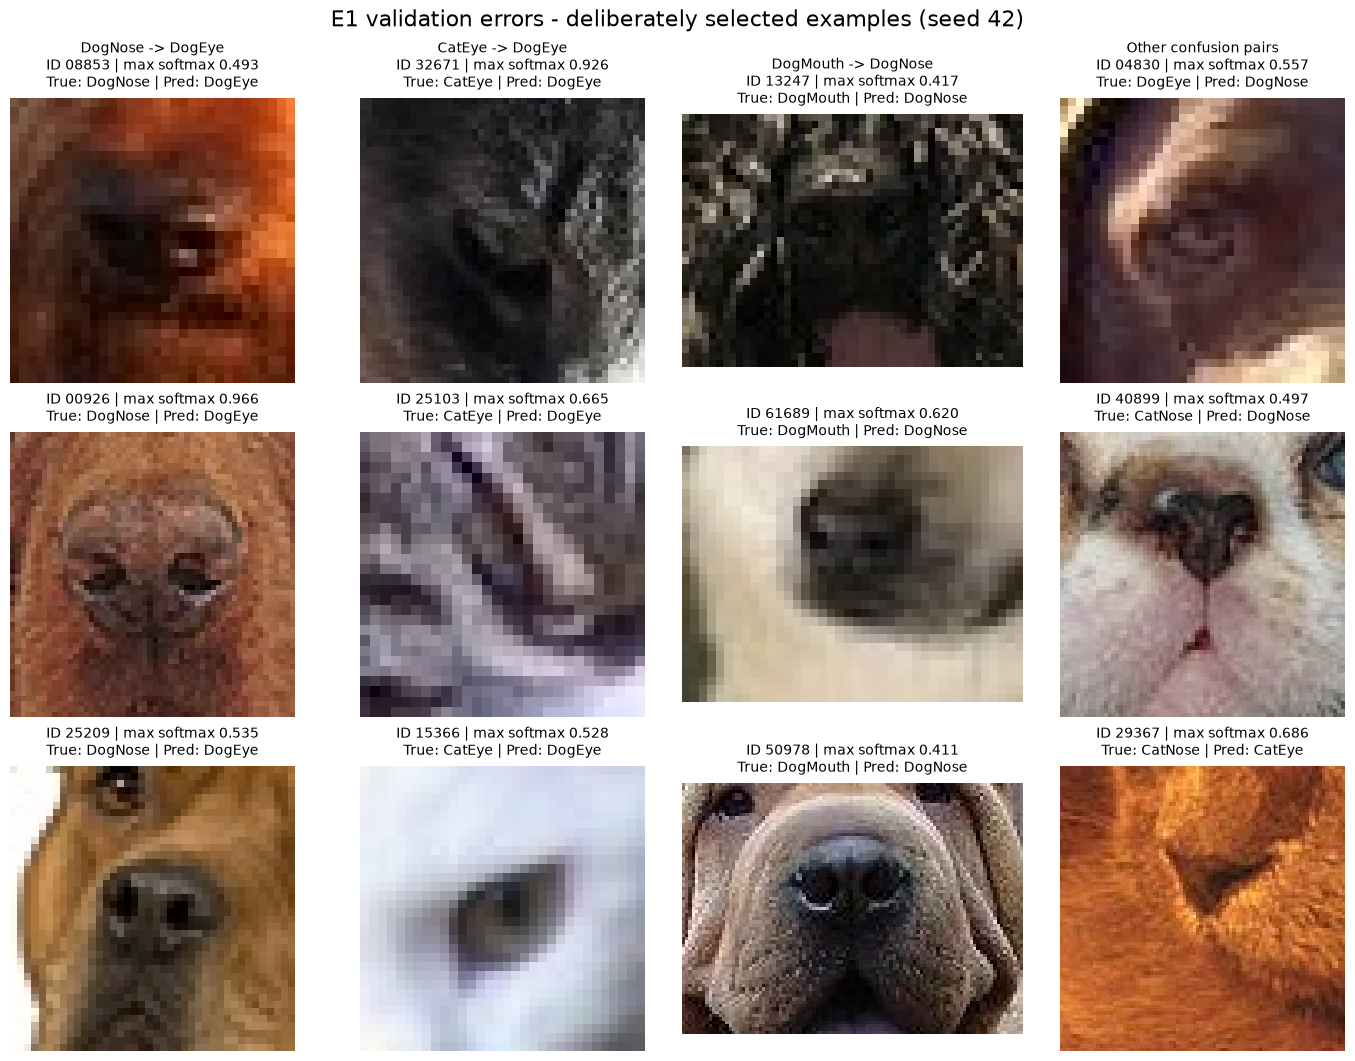

saved_gallery_exists: PASS
existing_evaluation_and_metadata_unchanged: PASS
selected_raw_images_unchanged: PASS
Saved: C:\Users\leoca\Kaggle-Competition\outputs\figures\E1_validation_error_gallery.png 
Saved: C:\Users\leoca\Kaggle-Competition\outputs\metrics\E1_error_analysis_check.json


In [4]:
TRAIN_DIR = (PROJECT_ROOT / "data/raw/train/train").resolve()
FIGURE_PATH = PROJECT_ROOT / "outputs/figures/E1_validation_error_gallery.png"
CHECK_PATH = PROJECT_ROOT / "outputs/metrics/E1_error_analysis_check.json"
validation_by_id = validation.set_index("image_id")
selected_by_id = selected.set_index("image_id")
column_titles = [f"{true} -> {predicted}" for true, predicted in TOP_PAIRS] + ["Other confusion pairs"]
fig, axes = plt.subplots(3, 4, figsize=(14, 10.5), layout="constrained")
records = []
image_hashes = {}
decode_warnings = []
for column, group in enumerate(selected_groups):
    for row, image_id in enumerate(group):
        prediction = selected_by_id.loc[image_id]
        original = validation_by_id.loc[image_id]
        require("selected_" + image_id + "_validation_error", original["split"] == "validation"
                and prediction["true_class"] == original["class"]
                and prediction["true_class"] != prediction["predicted_class"])
        assert len(image_id) == 5 and image_id.isascii() and image_id.isdigit()
        path = TRAIN_DIR / (image_id + ".jpg")
        assert path.resolve().parent == TRAIN_DIR and not path.is_symlink()
        assert path == PROJECT_ROOT / original["image_path"]
        image_hashes[image_id] = sha256(path)
        assert image_hashes[image_id] == original["byte_sha256"]
        # Decode exactly this original; conversion only prepares an RGB display.
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            with Image.open(path) as image:
                image.load()
                width, height = image.size
                mode = image.mode
                rgb = image.convert("RGB")
        for warning in caught:
            message = f"{image_id}: {warning.category.__name__}: {warning.message}"
            decode_warnings.append(message)
            print("DECODING WARNING:", message)
        ax = axes[row, column]
        ax.imshow(rgb, aspect="equal")
        rgb.close()
        title = (column_titles[column] + "\n") if row == 0 else ""
        title += (f"ID {image_id} | max softmax {prediction['max_softmax_confidence']:.3f}\n"
                  f"True: {prediction['true_class']} | Pred: {prediction['predicted_class']}")
        ax.set_title(title, fontsize=10, pad=8)
        ax.axis("off")
        records.append({"image_id": image_id, "true_class": prediction["true_class"],
                        "predicted_class": prediction["predicted_class"],
                        "max_softmax_confidence": float(prediction["max_softmax_confidence"]),
                        "width": width, "height": height, "mode": mode,
                        "image_path": original["image_path"], "byte_sha256": image_hashes[image_id],
                        "selection_group": column_titles[column]})
require("twelve_images_decoded", len(records) == 12)
fig.suptitle("E1 validation errors - deliberately selected examples (seed 42)", fontsize=16)
FIGURE_PATH.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(FIGURE_PATH, dpi=300, facecolor="white")
plt.show()
plt.close(fig)
require("saved_gallery_exists", FIGURE_PATH.is_file() and FIGURE_PATH.stat().st_size > 0)
require("existing_evaluation_and_metadata_unchanged", all(sha256(path) == input_hashes[name] for name, path in paths.items()))
require("selected_raw_images_unchanged", all(sha256(TRAIN_DIR / (image_id + ".jpg")) == digest
                                           for image_id, digest in image_hashes.items()))
summary = {
    "status": "passed", "analysis_only": True, "model_loaded_or_run": False,
    "validation_samples": len(validation), "correct": len(validation) - len(errors), "errors": len(errors),
    "error_rate": len(errors) / len(validation), "class_order": classes,
    "confusion_matrix": confusions["E1"].tolist(), "confusion_pairs": pairs.to_dict(orient="records"),
    "per_class_f1_comparison": comparison.to_dict(orient="records"),
    "seed": SEED, "random_generator": "Python random.Random",
    "selection_rule": "Top three pairs by descending count, true/predicted class tie-break; sort IDs before sampling three per pair without replacement; then sort pooled remaining-pair IDs and sample three with the same RNG. Gallery columns are selection groups.",
    "selected_ids": selected_ids, "selected_images": records,
    "input_sha256": input_hashes, "figure_path": FIGURE_PATH.relative_to(PROJECT_ROOT).as_posix(),
    "figure_sha256": sha256(FIGURE_PATH), "checks": checks,
    "failed_checks": [name for name, passed in checks.items() if not passed], "warnings": decode_warnings,
    "limitations": ["Deliberately selected gallery is not an estimate of error frequencies.",
                    "Maximum softmax confidence is not calibrated certainty.",
                    "No visual causes or label errors are inferred; unknown related crops may remain."]
}
CHECK_PATH.parent.mkdir(parents=True, exist_ok=True)
CHECK_PATH.write_text(json.dumps(summary, indent=2, allow_nan=False) + "\n", encoding="utf-8")
print("Saved:", FIGURE_PATH, "\nSaved:", CHECK_PATH)